# 15 · Trusting the result: IS against MCMC

**Level:** advanced · **Prerequisites:** [13](13_profile_importance_sampling.ipynb) · **Run time:** ~2 min (~30 s with `PIZZETTI_SMOKE=1`)

**Covers:** the Monte Carlo noise of importance sampling and of emcee, measured the same way; why a chain of 50
autocorrelation times under-samples slow tails; more importance draws as a cheap check; the cost of each

How do we know that `fit()` returned the right posterior? The usual check is to compare with MCMC. But a converged
MCMC chain is itself a Monte Carlo estimate, with its own noise, largest in the tails, exactly where importance
sampling and MCMC tend to differ. This notebook measures both noises on the light curve of notebooks 02–06 and
13, against a long reference chain.

In [1]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pizzetti

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"
warnings.filterwarnings("ignore", category=RuntimeWarning)

truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=0.40, u2=0.25)
sigma = 500e-6
t_one = np.arange(-0.13, 0.13, 2.0 / 1440)
t = (np.arange(7)[:, None] * truth["per"] + t_one[None, :]).ravel()
p_true = pizzetti.TransitParams()
p_true.t0, p_true.per, p_true.rp, p_true.a = truth["t0"], truth["per"], truth["rp"], truth["a"]
p_true.inc = np.degrees(np.arccos(truth["b"] / truth["a"]))
p_true.ecc, p_true.w, p_true.limb_dark, p_true.u = 0.0, 90.0, "quadratic", [truth["u1"], truth["u2"]]
f_true = pizzetti.TransitModel(p_true, t, series_tol=0.0, limb="quadrature").light_curve(p_true)
y = f_true + sigma * np.random.default_rng(42).standard_normal(t.size)
model = pizzetti.MarginalTransitModel(p_true, t, y, sigma, free=["t0", "per", "rp", "a", "b"],
                                      bounds={"rp": (0, 0.5), "a": (1.5, 100)})
free = model.free

## The accuracy measure

As in the paper and notebook 13: the 2.5, 16, 50, 84 and 97.5% quantiles of every parameter, one sample against
another, in units of the reference posterior standard deviation; the largest difference over all parameters and
quantiles. It is dominated by the outer quantiles, where every Monte Carlo method is noisiest.

In [2]:
QS = (0.025, 0.16, 0.5, 0.84, 0.975)

def wquantiles(x, w):
    o = np.argsort(x)
    cw = np.cumsum(w[o]); cw /= cw[-1]
    return np.interp(QS, cw - 0.5 * w[o] / w.sum(), x[o])

def max_dev(A, wa, B, wb, sd):
    # A, B: draws (columns = free parameters) with weights; sd: reference standard deviations
    return max(np.max(np.abs(wquantiles(A[:, j], wa) - wquantiles(B[:, j], wb))) / sd[j] for j in range(len(sd)))

## A long reference chain

emcee on the marginal posterior for 40 000 steps with 32 walkers, several hundred autocorrelation times. Its own
noise is small enough to serve as the truth here.

In [3]:
def run_chain(nsteps, seed):
    p0 = (np.array([truth[q] for q in free])
          + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02]) * np.random.default_rng(seed).standard_normal((32, 5)))
    s = model.EnsembleSampler(32)
    s.random_state = np.random.RandomState(seed).get_state()
    s.run_mcmc(p0, nsteps, progress=False)
    return s

t_start = time.perf_counter()
s_ref = run_chain(4000 if SMOKE else 40_000, seed=100)
tau = s_ref.get_autocorr_time(tol=0)
ref_phys = s_ref.get_chain(discard=int(5 * tau.max()), flat=True, expand=False)   # physical t0, per, rp, a, b
print(f"reference: {s_ref.iteration} steps = {s_ref.iteration / tau.max():.0f} autocorrelation times "
      f"(max tau {tau.max():.0f}), {time.perf_counter() - t_start:.0f} s")
sd = ref_phys.std(axis=0)
w_ref = np.ones(len(ref_phys))

reference: 40000 steps = 297 autocorrelation times (max tau 135), 30 s


## Run-to-run noise: emcee at 50 autocorrelation times

Several independent emcee runs, each stopped as soon as it is 50 autocorrelation times long with a stable τ, the
convergence criterion of notebooks 06, 12 and 13 and of the paper's reference chains.

In [4]:
def run_to_convergence(seed, ntau=(10 if SMOKE else 50), check=500):
    p0 = (np.array([truth[q] for q in free])
          + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02]) * np.random.default_rng(seed).standard_normal((32, 5)))
    s = model.EnsembleSampler(32)
    s.random_state = np.random.RandomState(seed).get_state()
    state, old = p0, np.inf
    while True:
        state = s.run_mcmc(state, check, progress=False)
        tau = s.get_autocorr_time(tol=0)
        if np.all(ntau * tau < s.iteration) and np.all(np.abs(old - tau) / tau < 0.01):
            break
        old = tau
    chain = s.get_chain(discard=int(5 * tau.max()), flat=True, expand=False)
    return chain, s.iteration * 32

mc_runs = []
for seed in range(2 if SMOKE else 6):
    chain, ev = run_to_convergence(seed)
    mc_runs.append((chain, ev))
    print(f"emcee seed {seed}: {ev:,} evaluations, vs reference {max_dev(chain, np.ones(len(chain)), ref_phys, w_ref, sd):.2f} sd")

emcee seed 0: 528,000 evaluations, vs reference 0.04 sd


emcee seed 1: 256,000 evaluations, vs reference 0.24 sd


emcee seed 2: 336,000 evaluations, vs reference 0.19 sd


emcee seed 3: 304,000 evaluations, vs reference 0.18 sd


emcee seed 4: 304,000 evaluations, vs reference 0.17 sd


emcee seed 5: 448,000 evaluations, vs reference 0.03 sd


## Run-to-run noise: profile importance sampling

The same for `fit()` with its default of 4000 draws.

In [5]:
is_runs = []
for seed in range(3 if SMOKE else 6):
    model.n_eval = 0
    r = model.fit(seed=seed)
    X, w = r.weighted_samples[:, :len(free)], r.weights
    is_runs.append((X, w, model.n_eval))
    print(f"IS seed {seed}: {model.n_eval:,} evaluations, k-hat {r.diagnostics['khat']:.2f}, "
          f"vs reference {max_dev(X, w, ref_phys, w_ref, sd):.2f} sd")

IS seed 0: 13,658 evaluations, k-hat 0.01, vs reference 0.05 sd


IS seed 1: 13,658 evaluations, k-hat 0.17, vs reference 0.15 sd


IS seed 2: 13,658 evaluations, k-hat 0.19, vs reference 0.18 sd


IS seed 3: 13,658 evaluations, k-hat 0.03, vs reference 0.05 sd


IS seed 4: 13,658 evaluations, k-hat 0.09, vs reference 0.05 sd


IS seed 5: 13,658 evaluations, k-hat 0.09, vs reference 0.08 sd


Both scatter around the reference by about the same amount, roughly 0.1–0.2 posterior standard deviations in
the worst quantile, and for the same reason: a few thousand effective draws pin down the 2.5% and 97.5% quantiles
only that well. A disagreement of this size between IS and a 50τ chain is not a sign that either is wrong. The
spread between two runs of the same method measures this noise directly, which is why the paper reports it next
to every comparison.

## The tail next to the wall

The probability of b < 0.15 lives in the slowest-mixing part of the posterior (notebook 12). Each run's estimate
scatters around the reference by a few tenths of a per cent:

reference P(b < 0.15) = 0.0482
emcee (50 tau): 0.0485, 0.0415, 0.0421, 0.0420, 0.0427, 0.0485   scatter 0.0030
IS (4000):      0.0500, 0.0471, 0.0390, 0.0488, 0.0468, 0.0478   scatter 0.0036


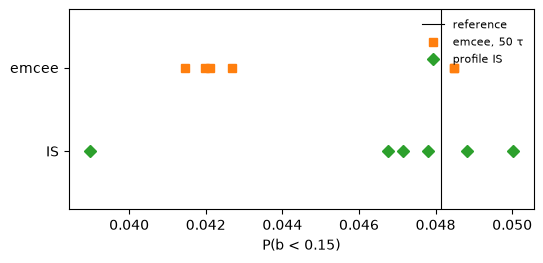

In [6]:
tail = lambda X, w: np.sum(w[X[:, 4] < 0.15]) / np.sum(w)
p_ref = tail(ref_phys, w_ref)
p_mc = [tail(c, np.ones(len(c))) for c, _ in mc_runs]
p_is = [tail(X, w) for X, w, _ in is_runs]
print(f"reference P(b < 0.15) = {p_ref:.4f}")
print("emcee (50 tau): " + ", ".join(f"{v:.4f}" for v in p_mc) + f"   scatter {np.std(p_mc):.4f}")
print("IS (4000):      " + ", ".join(f"{v:.4f}" for v in p_is) + f"   scatter {np.std(p_is):.4f}")
plt.figure(figsize=(6, 2.6))
plt.axvline(p_ref, color="k", lw=0.8, label="reference")
plt.plot(p_mc, np.full(len(p_mc), 1), "s", color="C1", label="emcee, 50 τ")
plt.plot(p_is, np.full(len(p_is), 0), "D", color="C2", label="profile IS")
plt.yticks([0, 1], ["IS", "emcee"]); plt.ylim(-0.7, 1.7); plt.xlabel("P(b < 0.15)")
plt.legend(frameon=False, fontsize=8, loc="upper right");

Here both methods do about equally well. When they do not, the culprit is often the chain: the autocorrelation
time estimated from a chain is itself underestimated when the chain has visited a slow region only a few times, so
a "converged" chain can stop too early. In the paper's extended tests, a CHEOPS light curve of 55 Cnc e showed
exactly this: two 50τ chains agreed with each other but put the 2.5% quantile of b
at 0.12, importance sampling at 0.08–0.09, and a chain run to 300τ (with a three times longer autocorrelation time
than the short chains had estimated) gave 0.081.

## A cheap check: more importance draws

The profile and its optimisations are a fixed cost; more draws only cost one evaluation each. A second run with
ten times the draws is an independent check that needs no MCMC: its Monte Carlo noise is about √10 smaller, so it
should agree with the first run within the first run's noise (0.1–0.2 sd in the worst quantile).

In [7]:
big = {}
for n in (4000, 40_000):
    model.n_eval = 0
    t_start = time.perf_counter()
    r = model.fit(seed=11, n=n)
    big[n] = (r.weighted_samples[:, :len(free)], r.weights)
    print(f"n = {n:6d}: {model.n_eval:7,} evaluations, {time.perf_counter() - t_start:4.1f} s, "
          f"ESS {r.diagnostics['ess']:6.0f}, P(b < 0.15) {tail(*big[n]):.4f}")
print(f"the two runs differ by {max_dev(*big[4000], *big[40_000], sd):.2f} sd in the worst quantile")

n =   4000:  13,658 evaluations,  0.5 s, ESS   2957, P(b < 0.15) 0.0409


n =  40000:  53,258 evaluations,  1.9 s, ESS  29567, P(b < 0.15) 0.0425
the two runs differ by 0.10 sd in the worst quantile


## Cost

Evaluations of the marginal likelihood per run, the same function for both methods:

In [8]:
ev_mc = np.median([ev for _, ev in mc_runs])
ev_is = np.median([ev for _, _, ev in is_runs])
print(f"emcee to 50 tau:   {ev_mc:10,.0f} evaluations (median)")
print(f"profile IS (fit):  {ev_is:10,.0f} evaluations (median)  ->  {ev_mc / ev_is:.0f}x fewer")

emcee to 50 tau:      320,000 evaluations (median)
profile IS (fit):      13,658 evaluations (median)  ->  23x fewer


In the paper's extended tests on 100 Kepler, K2, TESS and CHEOPS light curves, profile importance sampling agreed
with the emcee references to within 0.28 posterior standard deviations (median 0.13), as closely as two
independent importance-sampling runs agreed with each other, with a median of 28 times fewer evaluations than
emcee on the marginal posterior and 79 times fewer than a conventional fit that samples the limb darkening.

## What you learned

- Compare samplers with the noise of each in mind: two runs of the same method show how much they can differ by
  chance, mostly in the outer quantiles.
- A chain of 50 autocorrelation times can still under-sample a slow tail; independent importance draws do not
  have that problem, and more of them are cheap.
- `fit()` reaches the accuracy of a converged emcee run at a fraction of its cost.

**Back to:** [the tutorial index](README.md)